In [1]:
import numpy as np, matplotlib.pyplot as plt
from dynesty_utils import *
from HItargets_utils import hi_planets_by_name, filter_loc, filter_lambda
import fspiderman as sp
from hyperillumination_phasecurve_utils import *
from simple_bias_analysis import binned
import time

In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
K2_141b = hi_planets_by_name("K2-141 b")

u = [0.15, 0.08]                            # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere, not from K2-141 data, will be set by theoretical stellar atmosphere models)
u_B = 0.6                                   # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)

A_B_true = 3/2 * 0.28 # 0.42 (Ag = 0.28 geometric albedo in the optical from Zieba 2022, placeholder)

# ASSUMPTION (!): Model for band-integrated albedo in MIRI/LRS band (MIR)
def A_model(A_B):
    # return A_B # Band-integrated albedo in MIR of rocky surface set to A=A_B (probably overestimate). Also, A_LRS and A_B are basically unrelated since >99% of stellar flux is below 5um - same actually goes for Spitzer: 98% under 3.7um.
    return .1 # Band-integrated albedo of rocky surface fixed to A=0.1 (small reflected part) in MIR

# Filter to be used
instrument = "MIRI/LRS"
lrs_path = filter_loc(instrument)
lrs_range = filter_lambda(instrument)

n_bins = 27 # number of bins in one orbit
sigma_1min      = 323. # detection error [ppm per minute], MIRI/LRS 5.0-10.5 um
n_orbits        = 3 # number of orbits observed (3 orbits has been done)

In [3]:
l1, l2 = lrs_range
stellar_grid = sp.stellar_grid.gen_grid(l1, l2, logg=4.5, response=lrs_path)

# context for simulating data functions
cfg = FittingConfig(planet=K2_141b, stellar_grid=stellar_grid, filter_path=lrs_path,
                 l1=l1, l2=l2, A_=A_model,
                 sigma_1min=sigma_1min, n_orbits=n_orbits, n_bins=n_bins, reflected=True, u_B=u_B, u=u)

print(f"period = {K2_141b.period*24*60:.1f} min -> {n_bins} bins of {K2_141b.period*24*60/n_bins:.1f} min")
print(f"1-sigma per bin (over all orbits) = {cfg.sigma_bin:.1f} ppm")

no stellar models provided, using blackbody approximation
period = 403.7 min -> 27 bins of 15.0 min
1-sigma per bin (over all orbits) = 48.2 ppm


### 1. Simulated Data

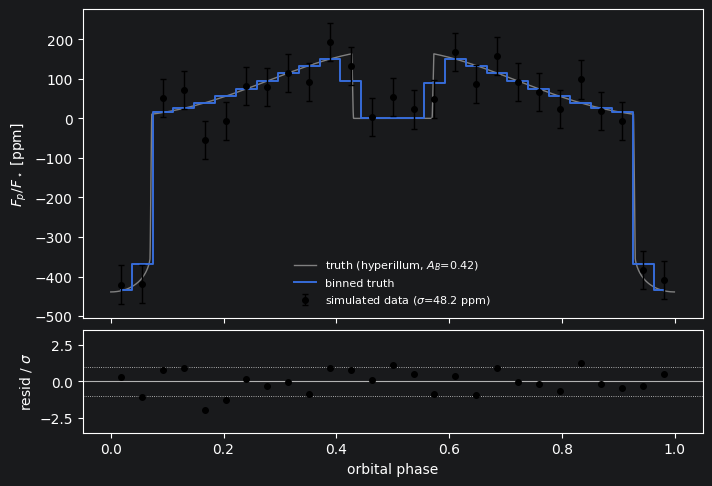

sigma_bin: 48.23 ppm  (bin width 14.95 min)
chi2 / n_bins (normalized average noise per bin ~1): 0.63
residual mean / sigma (~0): -0.03


In [4]:
# Full Phase Curve (for custom reproduction of simulate_data)
t_hi, y_hi = model_pcurve(cfg, "hyperillum", A_B_true, n_t=200 * cfg.n_bins, n_layers=80, n_lo=600, n_la=300)
y_true = binned(cfg, y_hi)

# SIMULATED OBSERVATION
data = simulate_data(cfg, A_B_true=A_B_true)
ph   = data["t"] / cfg.planet.period  # orbital phase
ph_hi = t_hi / cfg.planet.period

# Plotting
fig, (ax, axr) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[3, 1], hspace=0.06))

ax.plot(ph_hi, y_hi, lw=1., color="0.5", label=f'truth (hyperillum, $A_B$={A_B_true:.2f})')
ax.step(ph, y_true, where="mid", color="C0", lw=1.4, label="binned truth")
ax.errorbar(ph, data["y_obs"], yerr=data["sigma"], fmt="o", ms=4, color="k", capsize=2,
            elinewidth=1., label=f'simulated data ($\\sigma$={cfg.sigma_bin:.1f} ppm)')
ax.set_ylabel("$F_p/F_\\star$ [ppm]"); ax.legend(frameon=False, fontsize=8); ax.margins(x=0.01)

r = (data["y_obs"] - y_true) / data["sigma"]
axr.axhline(0, color="0.7", lw=0.8); axr.axhline(1, color="0.85", lw=0.6, ls=":")
axr.axhline(-1, color="0.85", lw=0.6, ls=":")
axr.plot(ph, r, "ko", ms=4)
axr.set_xlabel("orbital phase"); axr.set_ylabel("resid / $\\sigma$"); axr.set_ylim(-3.5, 3.5)
plt.show()

# ── numerical checks ───────────────────────────────────────────────────────────────────────
chi2 = np.sum(r**2)
print(f"sigma_bin: {cfg.sigma_bin:.2f} ppm  (bin width {cfg.planet.period*24*60/cfg.n_bins:.2f} min)")
print(f"chi2 / n_bins (normalized average noise per bin ~1): {chi2/cfg.n_bins:.2f}")
print(f"residual mean / sigma (~0): {r.mean():.2f}")

### 2. Likelihood `GaussianLogL`

This is the object dynesty wants as `loglike`: a picklable, module-level callable`theta -> lnL`, where `theta` is ordered by `names` (that ordering is also the column order of`res.samples`). Anything `model_pcurve` needs that is *not* sampled goes into `fixed`.$$\ln\mathcal{L}(\theta) = -\tfrac{1}{2}\sum_i\left[\left(\frac{y_i-m_i(\theta)}{s_i}\right)^2 + \ln\left(2\pi s_i^2\right)\right]$$The $\ln(2\pi s^2)$ term is $\theta$-independent and cancels in Bayes factors on identical data,but keeping it makes $\ln Z$ a properly normalised evidence.Two geometry-only caches are built automatically and are **bit-identical** to recomputing:`reflected_unit` (reflected light is exactly linear in $A$) and the insolation map($T(A_B)=T(A_B{=}0)\,(1-A_B)^{1/4}$ exactly, so the order-64 penumbra integral is A_B-independent).Each is dropped as soon as a parameter it depends on is sampled — `logl.cache_used` says which survived.

In [5]:
# uniform priors
A_B_BOUNDS = (0.0, 0.8)
OFF_BOUNDS = (-50., 50.)

A_grid = np.linspace(*A_B_BOUNDS, 61)
O_grid = np.linspace(*OFF_BOUNDS, 121)

base   = dict(A_B=A_B_true, offset=0.)

# same data, same priors -> the two lnZ are comparable
logl_h = GaussianLogL(cfg, data, "hyperillum", names=("A_B", "offset"))
logl_n = GaussianLogL(cfg, data, "naive",      names=("A_B", "offset"))

for L in (logl_h, logl_n):
    th = theta_of(L, dict(A_B=A_B_true, offset=0.))
    L(th)  # warm up
    t0 = time.perf_counter(); val = L(th); dt = time.perf_counter() - t0
    print(f"{L!r}")
    print(f"   lnL(truth) = {val:9.2f}   chi2 = {L.chi2(th):6.1f} / {cfg.n_bins} bins"
          f"   {dt*1e3:6.0f} ms/call  ->  {dt*1e4/60:.0f} min per 1e4 calls (serial)")

GaussianLogL(hyperillum, names=('A_B', 'offset'), fixed={}, ndim=2, caches=('refl', 'insol'))
   lnL(truth) =   -137.88   chi2 =   16.8 / 27 bins      127 ms/call  ->  21 min per 1e4 calls (serial)
GaussianLogL(naive, names=('A_B', 'offset'), fixed={}, ndim=2, caches=('refl', 'insol'))
   lnL(truth) =   -137.68   chi2 =   16.4 / 27 bins      212 ms/call  ->  35 min per 1e4 calls (serial)


#### 2.1 &nbsp;1-D slices

Plotted as $\Delta\ln\mathcal{L}=\ln\mathcal{L}-\ln\mathcal{L}_{\max}$, so the dotted lines at$-0.5,-2,-4.5$ are the 1-parameter $1/2/3\sigma$ levels.Scanning `offset` is free — it enters additively, so the whole slice comes from one forward model.

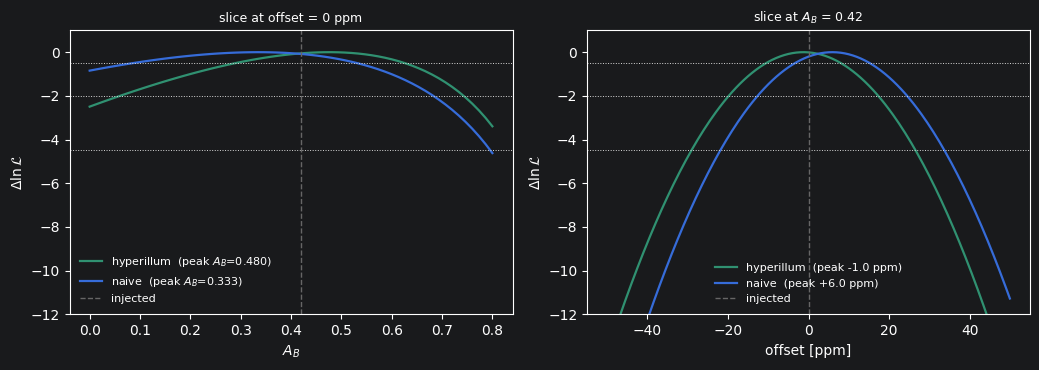

In [6]:
A_grid = np.linspace(*A_B_BOUNDS, 61)         # 61 forward models per insolation model
O_grid = np.linspace(*OFF_BOUNDS, 201)        # free (additive)

fig, (axA, axO) = plt.subplots(1, 2, figsize=(10.5, 3.8))
for L, c, lab in ((logl_h, "C3", "hyperillum"), (logl_n, "C0", "naive")):
    sA = logl_slice(L, "A_B",    A_grid, base, n_jobs=-1)
    sO = logl_slice(L, "offset", O_grid, base, n_jobs=-1)
    axA.plot(A_grid, sA - sA.max(), color=c, lw=1.6, label=f"{lab}  (peak $A_B$={A_grid[sA.argmax()]:.3f})")
    axO.plot(O_grid, sO - sO.max(), color=c, lw=1.6, label=f"{lab}  (peak {O_grid[sO.argmax()]:+.1f} ppm)")

for ax, truth, xl in ((axA, A_B_true, "$A_B$"), (axO, 0., "offset [ppm]")):
    for d in (-0.5, -2.0, -4.5):
        ax.axhline(d, color="0.85", lw=0.7, ls=":")
    ax.axvline(truth, color="0.4", lw=1.0, ls="--", label="injected")
    ax.set_xlabel(xl); ax.set_ylabel(r"$\Delta\ln\mathcal{L}$")
    ax.set_ylim(-12, 1.); ax.legend(frameon=False, fontsize=8)
axA.set_title(f"slice at offset = {base['offset']:g} ppm", fontsize=9)
axO.set_title(f"slice at $A_B$ = {base['A_B']:g}", fontsize=9)
plt.tight_layout(); plt.show()

#### 2.2 &nbsp;2-D map - the shape dynesty has to sample
With a **uniform** prior, $\exp(\ln\mathcal{L})$ over this box *is* the un-normalised posterior, so this map is a direct preview of the corner plot the sampler should return. Contours are the 2-parameter $1/2/3\sigma$ levels ($\Delta\ln\mathcal{L}=-1.15,-3.09,-5.91$).

naive: 61 forward models in 1.1 s   (caches: ('refl', 'insol'))
grid MAP: A_B = 0.4533, offset = +7.00 ppm, lnL = -137.47


NameError: name 'INSOL_TRUTH' is not defined

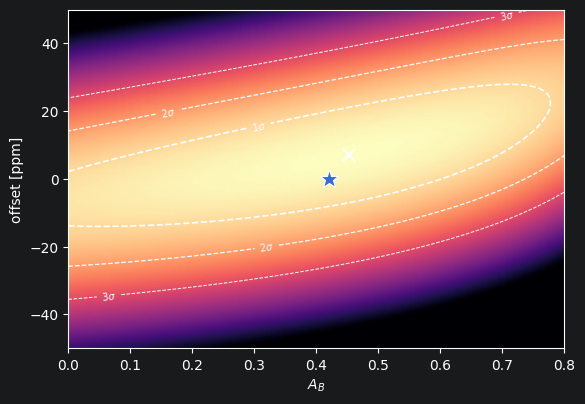

In [7]:
# TODO: add rp_rs vs A_B plot

for L in (logl_n, logl_h):
    t0 = time.perf_counter()
    Z  = logl_grid(L, "A_B", A_grid, "offset", O_grid, base, n_jobs=-1)   # (n_off, n_A_B)
    lnLmax, (off_map, A_map) = grid_max(Z, O_grid, A_grid)
    print(f"{L.insolation_model}: {len(A_grid)} forward models in {time.perf_counter()-t0:.1f} s   (caches: {L.cache_used})")
    print(f"grid MAP: A_B = {A_map:.4f}, offset = {off_map:+.2f} ppm, lnL = {lnLmax:.2f}")

    fig, ax = plt.subplots(figsize=(6.4, 4.4))
    im = ax.pcolormesh(A_grid, O_grid, Z - lnLmax, vmin=-15, vmax=0., cmap="magma", shading="gouraud")
    cs = ax.contour(A_grid, O_grid, Z - lnLmax, levels=[-5.91, -3.09, -1.15], colors="w", linewidths=[0.7, 0.9, 1.2])
    ax.clabel(cs, fmt={-5.91: r"3$\sigma$", -3.09: r"2$\sigma$", -1.15: r"1$\sigma$"}, fontsize=7)
    ax.plot(A_B_true, 0., "*", ms=14, mfc="C0", mec="w", mew=.8, label="injected")
    ax.plot(A_map, off_map, "x", ms=9, color="w", mew=1.6, label="grid MAP")
    ax.set_xlabel("$A_B$"); ax.set_ylabel("offset [ppm]")
    ax.set_title(f"$\\Delta\\ln\\mathcal{{L}}$  —  {L.insolation_model} model vs {INSOL_TRUTH} data", fontsize=9)
    ax.legend(loc="lower right", fontsize=8, labelcolor="w", facecolor="0.15", edgecolor="none", framealpha=.55)
    fig.colorbar(im, ax=ax, label=r"$\Delta\ln\mathcal{L}$")
    plt.tight_layout(); plt.show()

####  2.3 &nbsp;Brute-force evidence - the reference $\ln Z$
With two free parameters the evidence is just a 2-D integral, so it can be computed directly:$$Z=\int \mathcal{L}(\theta)\,\pi(\theta)\,\mathrm{d}\theta,\qquad \pi=\text{const}=\prod_k (\mathrm{hi}_k-\mathrm{lo}_k)^{-1}$$

In [ ]:
A_fine = np.linspace(*A_B_BOUNDS, 201)
O_fine = np.linspace(*OFF_BOUNDS, 401)

lnZ = {}
for L in (logl_n, logl_h):
    Zf = logl_grid(L, "A_B", A_fine, "offset", O_fine, base, n_jobs=-1)
    lnZ[L.insolation_model], edge = evidence_bruteforce(Zf, [O_fine, A_fine], bounds=[OFF_BOUNDS, A_B_BOUNDS])
    # convergence check: same integral on every 2nd node, no extra model calls
    lnZ_half, _ = evidence_bruteforce(Zf[::2, ::2], [O_fine[::2], A_fine[::2]], bounds=[OFF_BOUNDS, A_B_BOUNDS])
    print(f"{L.insolation_model:11s} lnZ = {lnZ[L.insolation_model]:9.4f}   (half-resolution {lnZ_half-lnZ[L.insolation_model]:+.1e},  edge_ratio {edge:.1e})")

lnB = lnZ["hyperillum"] - lnZ["naive"]
print(f"\nln B (hyperillum vs naive) = {lnB:+.3f}   ->  B = {np.exp(lnB):.3g}")
print("Jeffreys: |lnB| < 1 inconclusive, 1-2.5 substantial, 2.5-5 strong, > 5 decisive")